# Hourly rhythms across kapanewon
Yogyakarta · JogjaPulse · Role 4

Open this notebook in Google Colab and choose **Runtime → Run all**. The notebook includes the upstream summary tables needed for this figure. The final cell displays the result and writes a PNG to the current directory.

In [1]:
from pathlib import Path
from io import BytesIO
import base64, zlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image

PRIMARY_PERIODS = ['2021_Dec','2022_Jan','2022_Feb_P1','2022_Feb_P2']
COLORS = {
    "education_campus": "#0072B2",
    "healthcare_hospital": "#CC6677",
    "commercial_mall": "#AA4499",
    "traditional_market": "#B57700",
    "tourism_site": "#00896B",
    "transit_hub": "#674EA7",
    "baseline_candidate": "#647482",
    "mixed_use": "#503E35",
    "no_selected_facility": "#CBD2D4",
}
LABELS = {
    "education_campus": "Campuses",
    "healthcare_hospital": "Hospitals",
    "commercial_mall": "Malls",
    "traditional_market": "Markets",
    "tourism_site": "Tourism",
    "transit_hub": "Transit",
    "baseline_candidate": "Baseline candidates",
    "mixed_use": "Mixed use",
    "no_selected_facility": "No selected facility mapped",
}
MISSING = "#d9dfe2"
BREAK = pd.Timestamp("2022-01-01")


PERIOD_NAMES = {
    "2021_Dec": "December 2021",
    "2022_Jan": "January 2022",
    "2022_Feb_P1": "February 1–15",
    "2022_Feb_P2": "February 16–28",
    "2022_Mar_Apr_Exploratory": "March–April (exploratory)",
}




## Source data
Snapshot of `data/gold/kapanewon_hourly_profile.parquet` generated by the merged project pipeline. Expand the folded cell to inspect the embedded data.

In [2]:
# @title Load the embedded summary tables
encoded = {'gold/kapanewon_hourly_profile': '...'}
tables = {k: pd.read_csv(BytesIO(zlib.decompress(base64.b64decode(v)))) for k,v in encoded.items()}
def read(layer,name,columns):
    return tables[f'{layer}/{name}'].copy()
def gold(name,columns):
    return read('gold',name,columns)
for name, frame in tables.items():
    print(name, frame.shape)
    display(frame.head(3))

gold/kapanewon_hourly_profile (12288, 14)


,sampling_period,kab_code,kab_kota,kapanewon_code,kapanewon,hour_wib,day_type,median_n_maids,mean_n_maids,median_pings_per_maid,observed_days,period_hourly_coverage,period_kind,is_peak_hour
0,2021_Dec,34.01,KULON PROGO,34.01.01,TEMON,0,weekday,29.0,28.826087,2.900000,23,0.998656,primary,False
1,2021_Dec,34.01,KULON PROGO,34.01.01,TEMON,0,weekend,25.5,25.375000,3.389583,8,0.998656,primary,False
2,2021_Dec,34.01,KULON PROGO,34.01.01,TEMON,1,weekday,18.0,17.347826,2.454545,23,0.998656,primary,False


## Build the figure
Compare weekday and weekend within each column using its shared color scale. The left column shows device presence and the right measures reporting intensity. The same ten districts appear in both rows.

In [3]:
def heading(fig, title, description):
    fig.suptitle(
        title + "\n" + description,
        x=0.025,
        ha="left",
        fontsize=16,
        color="#163c45",
        fontweight="medium",
    )

def save(fig, path):
    fig.savefig(path, dpi=155, bbox_inches="tight", facecolor="white")
    plt.close(fig)

def diurnal(path, period):
    data = gold(
        "kapanewon_hourly_profile",
        "sampling_period kapanewon_code kapanewon hour_wib day_type median_n_maids median_pings_per_maid is_peak_hour",
    )
    data = data[data.sampling_period.eq(period)]
    if data.empty:
        raise ValueError(f"No hourly profile for {period}")
    order = (
        data.groupby("kapanewon_code")
        .median_n_maids.median()
        .dropna()
        .sort_values(ascending=False, kind="stable")
        .head(10)
        .index
    )
    names = data.drop_duplicates("kapanewon_code").set_index("kapanewon_code").kapanewon
    fig, axes = plt.subplots(2, 2, figsize=(15, 8), layout="constrained")
    for j, (metric, title) in enumerate(
        [
            ("median_n_maids", "Median observed devices"),
            ("median_pings_per_maid", "Median pings per device"),
        ]
    ):
        grids = [
            data[data.day_type.eq(day)]
            .pivot(index="kapanewon_code", columns="hour_wib", values=metric)
            .reindex(index=order, columns=range(24))
            for day in ("weekday", "weekend")
        ]
        palette = plt.get_cmap(("YlGnBu", "magma")[j]).copy()
        palette.set_bad(MISSING)
        for ax, grid, day in zip(axes[:, j], grids, ("weekday", "weekend")):
            im = ax.imshow(
                grid,
                aspect="auto",
                vmin=0,
                vmax=np.nanmax(np.asarray(grids)),
                cmap=palette,
            )
            ax.set(
                yticks=range(len(order)),
                yticklabels=names.loc[order].str.title(),
                xticks=range(0, 24, 2),
                xlabel="Hour (WIB)",
                title=f"{day.title()}  |  {title}",
            )
            if j == 0:
                for row in data[
                    data.day_type.eq(day)
                    & data.is_peak_hour
                    & data.kapanewon_code.isin(order)
                ].itertuples():
                    ax.plot(
                        row.hour_wib,
                        order.get_loc(row.kapanewon_code),
                        "wo",
                        ms=5,
                        mec="black",
                    )
        fig.colorbar(
            im,
            ax=axes[:, j].tolist(),
            orientation="horizontal",
            shrink=0.8,
            pad=0.06,
            label=title,
        )
    peaks = data[
        data.is_peak_hour
        & data.day_type.eq("weekday")
        & data.kapanewon_code.isin(order)
    ].dropna(subset=["median_n_maids"])
    result = "Weekday peak hours are unavailable."
    if not peaks.empty:
        peak = peaks.loc[peaks.median_n_maids.idxmax()]
        result = (
            f"{peak.kapanewon.title()} had the highest weekday device count shown, "
            f"peaking at {int(peak.hour_wib):02d}:00 WIB."
        )
    heading(
        fig,
        f"Hourly rhythms across ten kapanewon  |  {PERIOD_NAMES.get(period, period)}",
        "What we built: The left shows devices by hour. The right shows how often they reported.\n"
        "Circles mark the busiest hour. Gray means data is missing.\n"
        f"What we found: {result}",
    )
    save(fig, path)

In [4]:
period = '2021_Dec' # @param ['2021_Dec','2022_Jan','2022_Feb_P1','2022_Feb_P2','2022_Mar_Apr_Exploratory']

findfont: Failed to find font weight medium for DejaVu Sans, now using 400.


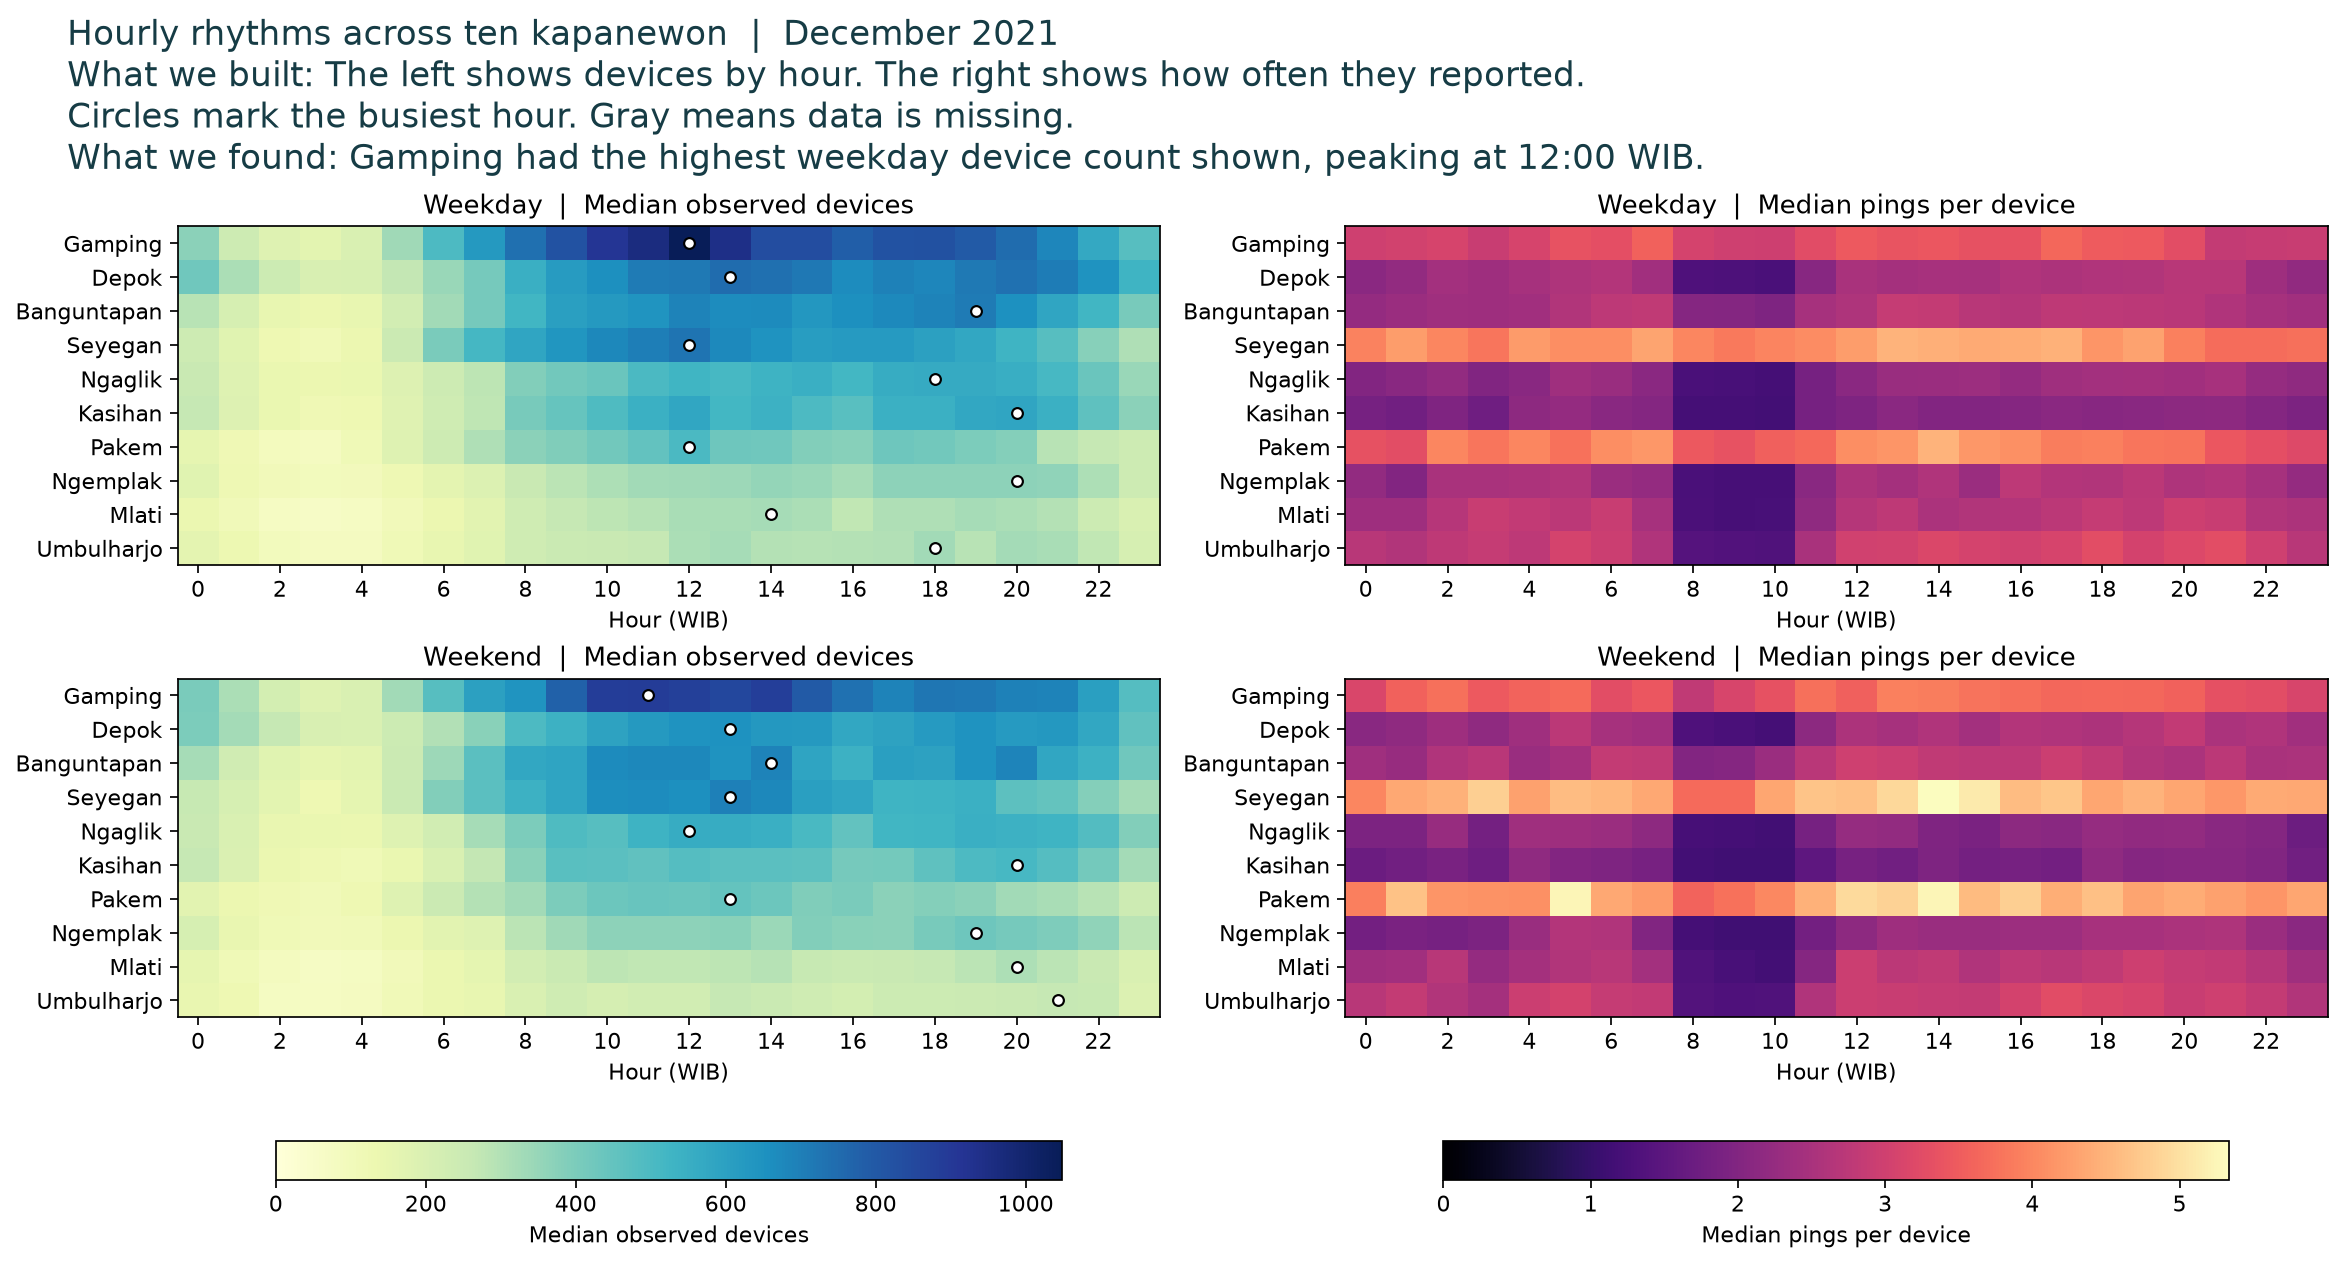

In [5]:
output = Path('kapanewon_diurnal_heatmap.png')
diurnal(output, period)
display(Image(filename=str(output)))